# Downturn LGD and the regulatory floors

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- identify downturn years from an indicator with `identify_downturn`, and say that the threshold is a policy parameter;
- reproduce the cohort-based downturn add-on of C08 with `downturn_add_on`, from the six cohort means and their numbers of defaults, and check it against the committed rows;
- judge whether a downturn estimate covers the realised downturn loss with `coverage_shortfall`, read the committed `downturn_coverage` tests and say why a green test and an open finding can sit together;
- read the LGD floors of the Basel III final framework with `lgd_floor` and `apply_lgd_floor`, and the EAD floor with `supervisory_ccf`, `ead_floor` and `apply_ead_floor`;
- say where each floor binds, and why in C08 and C09 none does.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import downturn, floors

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Eight committed artifacts. Seven are of case C08, the LGD of small-business loans: the six default-cohort variants `dc-2003-06.json` to `dc-2020-23.json` and the model artifact `models-dc-2007-08.json`, which holds the floors table. The eighth is `data/derived/C09/level-3.json`, the revolving-lines generator of case C09 at acceleration level 3, for the EAD floor. The LGD is the charge-off proxy of notebook 01, so the downturn figures below are a statement about the proxy. The artifacts were baked by older engines than the installed one, and the next cell prints the versions.

The downturn block is a fact of the whole file, not of one cohort: the long-run LGD is taken over the six cohorts, so every variant holds the same table. The cell loads the artifacts, checks that claim by comparing two variants, and prints the period the artifact reports and how it was found.

In [2]:
# Load the artifacts, check that the downturn block is the same in two variants and print its period and approach
ROOT = Path("../../..").resolve()
C08, C09 = ROOT / "data" / "derived" / "C08", ROOT / "data" / "derived" / "C09"
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((C08 / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
models = json.loads((C08 / "models-dc-2007-08.json").read_text(encoding="utf-8"))
level3 = json.loads((C09 / "level-3.json").read_text(encoding="utf-8"))
print("C08 variants baked by riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in cohort.values()}), "| C09:", level3["provenance"]["riskvalidation_version"], "| installed:", rv.__version__)
block = cohort["2007-08"]["outputs"]["downturn"]
print("same block in the 2007-08 and 2009-10 variants:", block == cohort["2009-10"]["outputs"]["downturn"])
print("downturn period found by the pipeline:", block["period"]["first_year"], "-", block["period"]["last_year"])
print("indicator:", block["period"]["indicator"])
print(block["approach"]["en"])

C08 variants baked by riskvalidation: ['1.0.1'] | C09: 1.0.1 | installed: 1.0.1
same block in the 2007-08 and 2009-10 variants: True
downturn period found by the pipeline: 2008 - 2011
indicator: annual charge-off rate of the SBA 7(a) book (charge-offs of the year over loans open on 1 January)
Cohort-based add-on: the default-weighted mean LGD proxy of the downturn cohorts minus the long-run mean over the six cohorts, with the downturn identified from the annual charge-off rate of the SBA 7(a) book. An illustration, not a regulatory estimate.


## Method

### Step 1: which years are a downturn?

The engine's `identify_downturn(years, indicator, threshold, higher_is_worse=True)` marks a year as a downturn year when the indicator is strictly above the threshold (a tie is not a downturn; a missing indicator raises an error). The engine does not choose the threshold: it is a **policy parameter**. The C08 pipeline sets it to the mean of the indicator plus one standard deviation of the years read, and uses as indicator the annual charge-off rate of the SBA 7(a) book itself, because no macro path is among its sources (the docstring of the pipeline's `downturn` module). The downturn is the longest run of consecutive flagged years.

The indicator values are not committed, only the period they gave. The next cell shows the rule on an **invented** indicator of eight years, to see the threshold and the flags; the real period is read in step 2.

In [3]:
# Apply identify_downturn to an invented indicator of eight years with a mean-plus-one-standard-deviation threshold
years = np.arange(2005, 2013)
rate = np.array([0.010, 0.012, 0.020, 0.050, 0.070, 0.040, 0.020, 0.015])
threshold = rate.mean() + 1.0 * rate.std()
flags = downturn.identify_downturn(years, rate, threshold)
print(f"threshold (mean + 1 standard deviation): {threshold:.4f}")
for year, value, flag in zip(years, rate, flags):
    print(f"{year}  indicator {value:.3f}  downturn year: {bool(flag)}")
print("a value equal to the threshold is not a downturn:", downturn.identify_downturn(np.array([2020]), np.array([0.05]), 0.05))

threshold (mean + 1 standard deviation): 0.0498
2005  indicator 0.010  downturn year: False
2006  indicator 0.012  downturn year: False
2007  indicator 0.020  downturn year: False
2008  indicator 0.050  downturn year: True
2009  indicator 0.070  downturn year: True
2010  indicator 0.040  downturn year: False
2011  indicator 0.020  downturn year: False
2012  indicator 0.015  downturn year: False
a value equal to the threshold is not a downturn: [False]


### Step 2: the cohort-based add-on

C08's downturn LGD is Contraste's own cohort-based add-on, an illustration and not a regulatory estimate (the EBA texts on downturn calibration are cross-references in the engine, and the engine states that it claims no regulatory approach). Two numbers are defined by default-weighted means:

$$\text{long-run} = \frac{\sum_k n_k\,\overline{LGD}_k}{\sum_k n_k}, \qquad \text{downturn} = \frac{\sum_{k \in D} n_k\,\overline{LGD}_k}{\sum_{k \in D} n_k}, \qquad \text{add-on} = \text{downturn} - \text{long-run}$$

where $k$ runs over the six cohorts, $\overline{LGD}_k$ is the mean proxy of cohort $k$, $n_k$ its number of defaults and $D$ the set of downturn cohorts. (Source: the docstring of `downturn_add_on`.) The pipeline's rule for $D$ is that a cohort is a downturn cohort when at least half of its default years are downturn years.

The next cell reads each cohort's years, mean and number of defaults from its own variant, applies the rule to the period of step 1's artifact (2008 to 2011), calls `downturn_add_on` and compares the result with the committed add-on. Every intermediate is printed.

In [4]:
# Mark the downturn cohorts by the half-of-the-years rule, call downturn_add_on and compare with the committed rows
first, last = block["period"]["first_year"], block["period"]["last_year"]
cohort_lgd, weights, mask = [], [], []
print(f"{'cohort':8s} {'default years':>20s} {'in the period':>16s} {'n':>8s} {'mean proxy':>14s} {'downturn cohort':>24s}")
for c in COHORTS:
    meta = cohort[c]["outputs"]["cohort"]
    span = range(meta["first_year"], meta["last_year"] + 1)
    inside = sum(first <= y <= last for y in span)
    is_down = inside / len(span) >= 0.5
    d = cohort[c]["outputs"]["lgd_distribution"]
    cohort_lgd.append(d["mean"]["value"]); weights.append(d["n"]); mask.append(is_down)
    print(f"{c:8s} {len(span):20d} {inside:16d} {d['n']:8,d} {d['mean']['value']:14.4f} {bool(is_down)!s:>24s}")

result = downturn.downturn_add_on(np.array(cohort_lgd), np.array(weights, float), np.array(mask))
committed = block["rows"][0]
print()
print(f"long-run LGD: {result.long_run:.6f} | downturn LGD: {result.downturn:.6f} | add-on: {result.add_on:.6f}")
print(f"committed:           {committed['long_run_lgd']['value']:.6f} | {committed['downturn_lgd']['value']:.6f} | {committed['add_on']:.6f}")
print("committed downturn cohorts:", [r["cohort_id"] for r in block["rows"]], "| the rule reproduces them:", [c for c, m in zip(COHORTS, mask) if m] == [r["cohort_id"] for r in block["rows"]])

cohort          default years    in the period        n     mean proxy          downturn cohort
2003-06                     4                0   21,919         0.7081                    False
2007-08                     2                1   25,299         0.8178                     True
2009-10                     2                2   50,281         0.8221                     True
2011-13                     3                1   33,673         0.7416                    False
2014-19                     6                0   36,481         0.6631                    False
2020-23                     4                0   13,930         0.7311                    False

long-run LGD: 0.753873 | downturn LGD: 0.820644 | add-on: 0.066770
committed:           0.753873 | 0.820644 | 0.066770
committed downturn cohorts: ['2007-08', '2009-10'] | the rule reproduces them: True


### Step 3: does the estimate cover the downturn loss?

An estimate that is supposed to hold in a downturn should be at least the loss realised in one. `coverage_shortfall(estimate, realised)` returns whether the estimate covers the realised value and by how much it falls short, with a tolerance of $10^{-12}$: $\text{covered} = \text{estimate} \ge \text{realised} - 10^{-12}$ and $\text{shortfall} = \max(0, \text{realised} - \text{estimate})$. The engine's test `downturn_coverage` adds the loan-level view: it tests whether the mean realised downturn LGD exceeds the estimate with a one-sided t statistic on the loans of the cohort, $t = (\overline{y} - \text{estimate}) / (s / \sqrt{n})$, and colours it with a Contraste internal gate (green when the p-value is at least 0.05, amber from 0.01, red below). The loans themselves are not committed, so the test rows are read from the artifact, with the engine version that baked them.

The cell applies `coverage_shortfall` to the two downturn cohorts and prints the committed test rows and the finding the pipeline recorded.

In [5]:
# Apply coverage_shortfall to the two downturn cohorts and print the committed downturn_coverage tests and the finding
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
for row in block["rows"]:
    covered, shortfall = downturn.coverage_shortfall(row["downturn_lgd"]["value"], row["crisis_realised_lgd"]["value"])
    print(f"cohort {row['cohort_id']}: estimate {row['downturn_lgd']['value']:.6f} realised {row['crisis_realised_lgd']['value']:.6f} -> covered {covered}, shortfall {shortfall:.6f} (committed: {row['covered']}, {row['shortfall']:.6f})")
print()
print("tests baked by riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["test_id"] == "lgd_ead.downturn_coverage":
        print(f"{t['segment']:17s} t={t['statistic']:7.4f} p={t['p_value']:.4f} shortfall={t['metric']:.6f} light: {LIGHT[t['light']]}")
for f in cohort["2007-08"]["findings"]:
    if f["id"] == "F-downturn-coverage":
        print("finding", f["id"], f["severity"], f["status"], "|", f["title"]["en"])

cohort 2007-08: estimate 0.820644 realised 0.817782 -> covered True, shortfall 0.000000 (committed: True, 0.000000)
cohort 2009-10: estimate 0.820644 realised 0.822083 -> covered False, shortfall 0.001440 (committed: False, 0.001440)

tests baked by riskvalidation: 1.0.1
cohort-2007-08    t=-1.4010 p=0.9194 shortfall=0.000000 light: green
cohort-2009-10    t= 0.9655 p=0.1671 shortfall=0.001440 light: green
finding F-downturn-coverage S3 open | The downturn LGD does not cover the realised loss of the cohorts 2009-10


The point estimate falls short of the realised loss of 2009-10 by a small amount, so the pipeline records an open finding of severity S3; the test cannot reject that the mean realised LGD is at or below the estimate, so its light is green. Both are true: a shortfall exists in the mean, and it is too small, against the dispersion of 50,281 proxies, to be statistically distinguishable from zero. A validator reads the two together and does not collapse them into one verdict.

### Step 4: the LGD floors

The Basel III final framework sets input floors for the LGD an advanced-approach bank may use, by portfolio and collateral (CRE32.16 for corporate, CRE32.58 and CRE32.59 for retail; the engine's `floors` module transcribes the cells from the research and marks the order of some retail cells UNVERIFIED against the paragraph text). `lgd_floor(portfolio, collateral)` returns the cell and raises for a combination with no cell. `apply_lgd_floor(lgd, floor)` returns the floored estimates, which loans the floor raises, the mean before and after and the uplift, $\max(\text{LGD}, \text{floor})$ loan by loan.

The next cell prints the floors table the C08 artifact carries and checks each cell against the engine's `lgd_floor`, so a changed table cannot go unnoticed. Then it applies the 25% corporate unsecured floor to eight **invented** LGDs, a mix of low and high values, to show what a binding floor does.

In [6]:
# Check the floors table of the artifact against lgd_floor and apply a 25% floor to eight invented LGDs
cells = models["fit"]["floors"]["cells"]
PORTFOLIO = {"corporate": "corporate", "retail": "retail"}
COLLATERAL = {"unsecured": "unsecured", "financial": "financial", "receivables": "receivables", "real-estate": "real estate",
              "other-physical": "other physical", "mortgage": "mortgage", "qrre": "qualifying revolving (QRRE)"}
print("regime:", "Basel III final", "(" + models["fit"]["floors"]["regime"] + ")")
agree = 0
for cell in cells:
    engine_floor = floors.lgd_floor(cell["portfolio"], cell["collateral"])
    agree += engine_floor == cell["floor"]
    print(f"{PORTFOLIO[cell['portfolio']]:12s} {COLLATERAL[cell['collateral']]:24s} floor {cell['floor']:.2f} engine {engine_floor:.2f} ({cell['reference'].replace(' to ', ' to ')})")
print(f"cells equal to the engine's: {agree} of {len(cells)}")

invented = np.array([0.03, 0.08, 0.15, 0.22, 0.30, 0.45, 0.60, 0.90])
bite = floors.apply_lgd_floor(invented, floors.lgd_floor("corporate", "unsecured"))
print()
print("invented LGDs:", invented)
print("after the floor:   ", bite.applied)
print(f"floor binds on {int(bite.binding.sum())} of {invented.size} (share {bite.share_binding:.3f}) | mean before {bite.mean_before:.4f} | mean after {bite.mean_after:.4f} | uplift {bite.uplift:.4f}")

regime: Basel III final (basel-iii-final)
corporate    unsecured                floor 0.25 engine 0.25 (CRE32.16)
corporate    financial                floor 0.00 engine 0.00 (CRE32.16)
corporate    receivables              floor 0.10 engine 0.10 (CRE32.16)
corporate    real estate              floor 0.10 engine 0.10 (CRE32.16)
corporate    other physical           floor 0.15 engine 0.15 (CRE32.16)
retail       mortgage                 floor 0.05 engine 0.05 (CRE32.58 to CRE32.59)
retail       qualifying revolving (QRRE) floor 0.50 engine 0.50 (CRE32.58 to CRE32.59)
retail       unsecured                floor 0.30 engine 0.30 (CRE32.58 to CRE32.59)
retail       financial                floor 0.00 engine 0.00 (CRE32.58 to CRE32.59)
retail       receivables              floor 0.10 engine 0.10 (CRE32.58 to CRE32.59)
retail       real estate              floor 0.10 engine 0.10 (CRE32.58 to CRE32.59)
retail       other physical           floor 0.15 engine 0.15 (CRE32.58 to CRE32.59)
cells e

### Step 5: where the LGD floor binds in C08

The C08 artifact applies the floors to the fractional-logit predictions of each cohort, by segment (`outputs.floors_bite`). The SBA file has no collateral field, so the pipeline infers the collateral from the term and the revolving status (lines of credit and loans up to 7 years as unsecured, 7 to 20 years as other physical, 20 years or more as real estate), as the artifact's own note says; the floor of each segment follows. The bite is the mean uplift. The cell prints the 2007-08 and 2009-10 tables and draws the mean predicted LGD of each segment against its floor.

Floors of dossier 01 A.5 applied to the L2-fractional-logit predictions of the cohort, by segment; the SBA file has no collateral field, so the collateral is inferred from the term and the revolving status (lines of credit and loans up to 7 years as unsecured, 7 to 20 years as other physical, 20 years or more as real estate). The bite is the mean uplift.

cohort 2007-08
  sme-revolver         corporate-unsecured        floor 0.25  n= 7,864  mean before 0.8903  share binding 0.000  uplift 0.0000
  sme-term-up-to-84    corporate-unsecured        floor 0.25  n=14,454  mean before 0.7254  share binding 0.000  uplift 0.0000
  sme-term-85-239      corporate-other-physical   floor 0.15  n= 2,739  mean before 0.6270  share binding 0.000  uplift 0.0000
  sme-term-240-plus    corporate-real-estate      floor 0.10  n=   242  mean before 0.6017  share binding 0.000  uplift 0.0000
cohort 2009-10
  sme-revolver         corporate-unsecured        floor 0.25  n=20,945  mean before 0.8809  share bindin

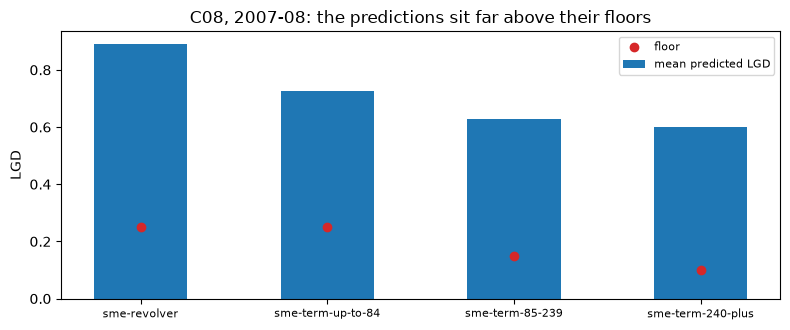

In [7]:
# Print the committed floors_bite tables of two cohorts and draw each segment's mean prediction against its floor
print(cohort["2007-08"]["outputs"]["floors_bite"]["note"]["en"])
print()
for c in ("2007-08", "2009-10"):
    rows = cohort[c]["outputs"]["floors_bite"]["rows"]
    print(f"cohort {c}")
    for r in rows:
        print(f"  {r['segment_id']:20s} {r['floor_id']:26s} floor {r['floor']:.2f}  n={r['n']:6,d}  mean before {r['mean_before']['value']:.4f}  share binding {r['share_binding']:.3f}  uplift {r['uplift']:.4f}")

rows = cohort["2007-08"]["outputs"]["floors_bite"]["rows"]
fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(len(rows))
ax.bar(positions, [r["mean_before"]["value"] for r in rows], width=0.5, color="tab:blue", label="mean predicted LGD")
ax.scatter(positions, [r["floor"] for r in rows], color="tab:red", zorder=3, label="floor")
ax.set_xticks(positions)
ax.set_xticklabels([r["segment_id"] for r in rows], fontsize=8)
ax.set_ylabel("LGD")
ax.set_title("C08, 2007-08: the predictions sit far above their floors")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 6: the EAD floor

The EAD floor of the same framework (CRE32.36 for corporate, CRE32.64 for retail) reads "on-balance amount plus 50% of the off-balance exposure using the standardised CCF". The engine's formula is $\text{floor} = E + s\,c\,\max(L - E, 0)$ with $s$ the off-balance share (0.5) and $c$ the supervisory conversion factor of the facility class, which `supervisory_ccf(item)` returns (for instance 0.4 for commitments, CRE20.98, and 0.1 for unconditionally cancellable lines, CRE20.100). The reading that the 50% applies to the CCF-weighted off-balance exposure follows the research wording and the engine marks it UNVERIFIED against the paragraph text. An overdrawn line has no off-balance amount, so its floor is its drawn amount. `apply_ead_floor(ead, floor)` takes the elementwise maximum.

The cell lists the five supervisory factors, applies the floor to three **invented** facilities (one of them overdrawn), and then reads what the C09 artifact reports for the same rule on its generator lines.

In [8]:
# List the supervisory CCFs, apply the EAD floor to three invented facilities and read the floor block of the C09 artifact
ITEM = {"direct-credit-substitutes": "direct credit substitutes", "nifs-rufs-transaction-related-contingents": "NIFs, RUFs and transaction-related contingents",
        "commitments": "commitments", "short-term-self-liquidating-trade-letters-of-credit": "short-term self-liquidating trade letters of credit",
        "unconditionally-cancellable": "unconditionally cancellable"}
for item in floors.SUPERVISORY_CCF:
    print(f"{ITEM[item]:75s} {floors.supervisory_ccf(item):.1f}")
drawn = np.array([20.0, 60.0, 110.0])
limit = np.array([100.0, 100.0, 100.0])
sa_ccf = np.array([floors.supervisory_ccf("commitments")] * 3)
floor_ead = floors.ead_floor(drawn, limit, sa_ccf)
estimate = np.array([40.0, 70.0, 105.0])
bite_ead = floors.apply_ead_floor(estimate, floor_ead)
print()
print("drawn:", drawn, "| limit:", limit)
print("EAD floor:", floor_ead, "| invented EAD estimates:", estimate, "| after the floor:", bite_ead.applied)
print(f"the floor binds on {int(bite_ead.binding.sum())} of {estimate.size}")
print()
eadf = level3["outputs"]["ead_floor"]
print("C09:", eadf["rule"])
for r in eadf["rows"]:
    print(f"  {ITEM[r['facility_class']]:36s} CCF {r['sa_ccf']:.1f} ({r['reference']}) n={r['n']:,} share binding {r['share_binding']:.3f} mean EAD before and after {r['mean_ead_before']:.2f} {r['mean_ead_after']:.2f}")

direct credit substitutes                                                   1.0
NIFs, RUFs and transaction-related contingents                              0.5
commitments                                                                 0.4
short-term self-liquidating trade letters of credit                         0.2
unconditionally cancellable                                                 0.1

drawn: [ 20.  60. 110.] | limit: [100. 100. 100.]
EAD floor: [ 36.  68. 110.] | invented EAD estimates: [ 40.  70. 105.] | after the floor: [ 40.  70. 110.]
the floor binds on 1 of 3

C09: on-balance amount + 50% of the off-balance exposure at the SA CCF (CRE32.36, CRE32.64)
  unconditionally cancellable          CCF 0.1 (CRE20.100) n=38,817 share binding 0.000 mean EAD before and after 5183.05 5183.05
  commitments                          CCF 0.4 (CRE20.98) n=38,817 share binding 0.000 mean EAD before and after 5183.05 5183.05


## Results

- **The threshold is a policy choice.** On the invented indicator the threshold (mean plus one standard deviation) is 0.0498, and only 2008 and 2009 lie above it; a value exactly at the threshold is not flagged.
- **The add-on is reproduced.** With the real period of 2008 to 2011, the half-of-the-years rule picks the cohorts 2007-08 (one of its two years inside the period) and 2009-10 (both). `downturn_add_on` gives a long-run LGD of 0.753873, a downturn LGD of 0.820644 and an add-on of 0.066770, equal to the committed rows to six decimals. The add-on is a difference of two means of a proxy, not a regulatory estimate.
- **A green test and an open finding coexist.** The estimate covers the realised loss of 2007-08 and falls short of 2009-10 by 0.001440. The `downturn_coverage` tests are green in both (p-values 0.9194 and 0.1671), and the pipeline keeps the finding open at severity S3: the shortfall exists in the mean and is small against the dispersion of 50,281 proxies.
- **The floors are a checked table.** All 12 cells of the artifact's floors table equal the engine's `lgd_floor`. On eight invented LGDs the 25% floor binds on four and lifts the mean from 0.3412 to 0.4062, an uplift of 0.0650.
- **In C08 and C09 no floor binds.** The mean predicted LGD of the C08 segments runs from 0.6017 to 0.8903 in 2007-08 against floors of 0.10 to 0.25, and every segment shows a share binding of 0.000 in 2007-08 and in 2009-10. The C09 EAD floor binds on none of the 38,817 defaulted lines under either supervisory factor. The invented EAD example does bind on one line of three, the overdrawn one, whose floor is its drawn amount of 110.

What the notebook does not do: it does not estimate a downturn LGD for a regulator or validate a floor. The proxy has high LGDs by construction, so a floor that matters in a low-LGD mortgage book does not matter here; the invented examples exist to show the arithmetic where it does. The next notebook measures the bias of the CCF estimators against the known truth of C09.

## Summary

- `identify_downturn` marks the years whose indicator is strictly above a threshold that is a policy parameter; the C08 pipeline takes the mean plus one standard deviation of the book's own annual charge-off rate and the longest run of flagged years.
- The cohort-based add-on is a difference of default-weighted means, `downturn_add_on`; it reproduces the committed rows once the half-of-the-years rule picks the cohorts. It is an illustration, not a regulatory estimate.
- Coverage is judged on the point estimate (`coverage_shortfall`) and on the loans (`downturn_coverage`); the two can differ, and both are reported.
- The LGD floors are a table by portfolio and collateral (`lgd_floor`, `apply_lgd_floor`) and the EAD floor is the drawn amount plus half of the CCF-weighted undrawn amount (`ead_floor`, `apply_ead_floor`). In C08 and C09 no floor binds.

**What to try next.** Lower the invented EAD estimates of step 6 and see the floor start to bind; apply the 5% retail mortgage floor to a set of low LGDs. Then continue with notebook 05, which measures how the choice of reference date biases the CCF.

## References

- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the LGD input floors, CRE32.16 and CRE32.58 to CRE32.59, and the EAD floor, CRE32.36 and CRE32.64, as transcribed in the engine's `floors` module). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- EBA/RTS/2018/04 and EBA/GL/2019/03 on downturn estimation: cross-references only in the engine's `downturn` module, which states that the add-on is Contraste's cohort-based one and claims no regulatory approach.
- The engine's own documentation: `riskvalidation.lgd_ead.downturn` and `riskvalidation.lgd_ead.floors` (release 0.8.1).
- This repository: `docs/design/SDD.md` (cases C08 and C09), `data-pipeline/pipeline/cases/c08/downturn.py` (the rule for the downturn cohorts) and `data/derived/C08/`, `data/derived/C09/level-3.json`.